In [121]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv')

In [122]:
df = data[['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year', 'fuel_efficiency_mpg']]
df.head(5)

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


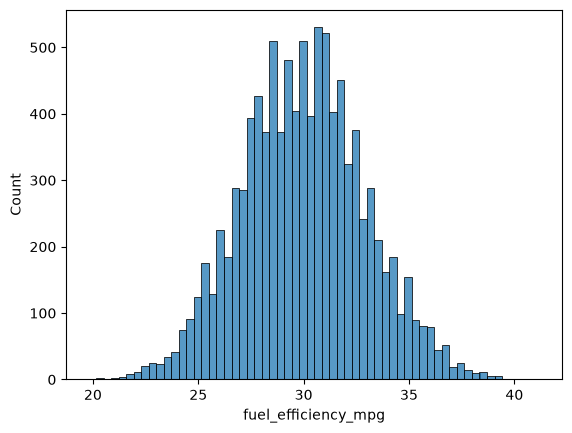

In [123]:
sns.histplot(df.fuel_efficiency_mpg)
plt.show()

In [124]:
df.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

In [125]:
df['horsepower'].median()

np.float64(254.0)

In [126]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train+n_val]]
df_test = df.iloc[idx[n_train+n_test:]]

In [127]:
y_train = np.log1p(df_train.fuel_efficiency_mpg.values)
y_val = np.log1p(df_val.fuel_efficiency_mpg.values)
y_test = np.log1p(df_test.fuel_efficiency_mpg.values)

del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [128]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(X.T).dot(y)
    
    return w[0], w[1:]

#
##
### Fill Null with 0

In [129]:
def fill_zero(df):
    df_num = df.fillna(0)
    X = df_num.values
    return X

In [130]:
X_train = fill_zero(df_train)
w_0, w = train_linear_regression(X_train, y_train)

y_pred = w_0 + X_train.dot(w)

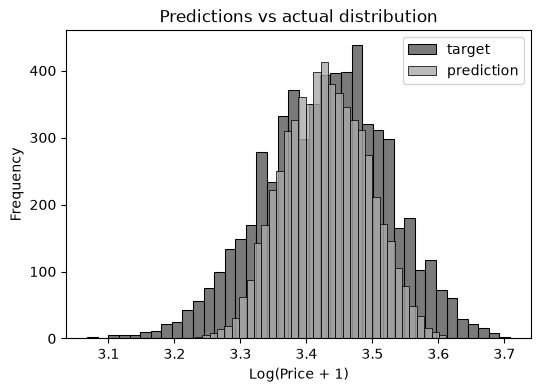

In [131]:
y_pred = w_0 + X_train.dot(w)
plt.figure(figsize=(6, 4))

sns.histplot(y_train, label='target', color='#222222', alpha=0.6, bins=40)
sns.histplot(y_pred, label='prediction', color='#aaaaaa', alpha=0.8, bins=40)

plt.legend()

plt.ylabel('Frequency')
plt.xlabel('Log(Price + 1)')
plt.title('Predictions vs actual distribution')

plt.show()

In [132]:
def rmse(y, y_pred):
    error = y_pred - y
    mse = (error ** 2).mean()
    return np.sqrt(mse)


rmse(y_train, y_pred) #training set score

np.float64(0.07127079986896064)

In [133]:
X_val = fill_zero(df_val)
y_pred = w_0 + X_val.dot(w)

rmse(y_val, y_pred) #validation set score

np.float64(0.07148851150946246)

#
##
## Fill Null with mean

In [134]:
def fill_mean(df):
    df_num = df.fillna(df.mean())
    X = df_num.values
    return X

In [135]:
X_train = fill_mean(df_train)
w_0, w = train_linear_regression(X_train, y_train)

y_pred = w_0 + X_train.dot(w)

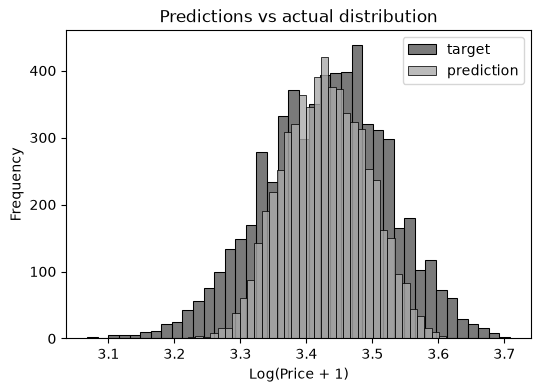

In [136]:
y_pred = w_0 + X_train.dot(w)
plt.figure(figsize=(6, 4))

sns.histplot(y_train, label='target', color='#222222', alpha=0.6, bins=40)
sns.histplot(y_pred, label='prediction', color='#aaaaaa', alpha=0.8, bins=40)

plt.legend()

plt.ylabel('Frequency')
plt.xlabel('Log(Price + 1)')
plt.title('Predictions vs actual distribution')

plt.show()

In [137]:
def rmse(y, y_pred):
    error = y_pred - y
    mse = (error ** 2).mean()
    return np.sqrt(mse)


rmse(y_train, y_pred) #training set score

np.float64(0.07121393746648459)

In [138]:
X_val = fill_mean(df_val)
y_pred = w_0 + X_val.dot(w)

rmse(y_val, y_pred) #validation set score

np.float64(0.07136831123141124)

#
## Regularization
###

In [139]:
def train_linear_regression_reg(X, y, r=0.0):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    reg = r * np.eye(XTX.shape[0])
    XTX = XTX + reg

    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(X.T).dot(y)
    
    return w[0], w[1:]

In [140]:
X_train = fill_zero(df_train)
X_val = fill_zero(df_val)

for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    w_0, w = train_linear_regression_reg(X_train, y_train, r=r)
    y_pred = w_0 + X_val.dot(w)
    print('%6s' %r, rmse(y_val, y_pred))

     0 0.07148851150946246
  0.01 0.07149325884153895
   0.1 0.07165023237517189
     1 0.07274035044832705
     5 0.0732791162252194
    10 0.07337041231450352
   100 0.07345871819237142


#
## Seed rotation
###

In [142]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

val_scores = []

for s in range(10):
    idx = np.arange(n)
    np.random.seed(s)
    np.random.shuffle(idx)

    df_train = df.iloc[idx[:n_train]].copy()
    df_val = df.iloc[idx[n_train:n_train+n_val]].copy()

    y_train = df_train.pop('fuel_efficiency_mpg').values #ignore log transformation
    y_val = df_val.pop('fuel_efficiency_mpg').values

    X_train = fill_zero(df_train)
    X_val = fill_zero(df_val)

    w_0, w = train_linear_regression(X_train, y_train)
    y_pred = w_0 + X_val.dot(w)

    val_scores.append(rmse(y_val, y_pred))

print(round(np.std(val_scores), 3))

0.029


#
## Using seed 9
###

In [150]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(9)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train+n_val]]
df_test = df.iloc[idx[n_train+n_test:]]

y_train = df_train.pop('fuel_efficiency_mpg').values
y_val = df_val.pop('fuel_efficiency_mpg').values
y_test = df_test.pop('fuel_efficiency_mpg').values

In [151]:
X_train = fill_zero(df_train)
X_test = fill_zero(df_test)

w_0, w = train_linear_regression_reg(X_train, y_train, r=0.001)
y_pred = w_0 + X_test.dot(w)

rmse(y_test, y_pred)

np.float64(2.2364156415997254)